# A6: how much do the Thai scores depend on the labels and on the sample

`src/evaluate.py` scores every Thai prediction three ways (`outputs/b/b9_results.csv`):

| scoring | patches | labels |
|---|---|---|
| (a) `worldcover` | 3,023 pure patches | WorldCover |
| (b) `clean-vote` | 199 hand-labelled patches | vote of three people (step A1) |
| (c) `clean-wc` | the same 199 patches | WorldCover |

Comparing them separates two effects:

- **(b) against (c): the effect of the labels.** Same patches, same predictions, only the labels change. If the scores agree, the noisy WorldCover labels do not distort the result.
- **(c) against (a): the effect of the sample.** Same kind of labels, different patches. If the scores differ, the 199 patches are not a miniature of the 3,023.

The notebook also asks how precise a score on only 199 patches is, and whether the small set ranks the methods in the same order as the large one.
Nothing is trained or predicted; the predictions come from `outputs/predictions/`. Runs: the seed 42 models of part B on the Thai patches.
Outputs go to `outputs/a6/`.

In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import spearmanr

import config as c

# colours on a light surface, as in A2 to A7
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SCORING_COLORS = {"worldcover": "#2a78d6", "clean-wc": "#eb6834", "clean-vote": "#1baf7a"}
SCORING_NAMES = {"worldcover": "(a) 3,023 patches, WorldCover", "clean-wc": "(c) 199 patches, WorldCover",
                 "clean-vote": "(b) 199 patches, human vote"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "x", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.family": "sans-serif", "font.size": 10,
})

OUT = c.OUTPUT_DIR / "a6"
OUT.mkdir(parents=True, exist_ok=True)
N_DRAWS = 2000


def save(fig, name):
    # Windows sometimes refuses to open a file that was written a moment ago, so retry a few times
    path = OUT / name
    for attempt in range(5):
        try:
            fig.savefig(path, dpi=130, bbox_inches="tight")
            break
        except OSError:
            if attempt == 4:
                raise
            time.sleep(1)
    print("saved", path)

## 1. Load labels, predictions and the existing scores

Scores are recomputed here with the same definition as `src/evaluate.py` (four Thai classes; a grassland prediction counts as wrong),
and checked against `b9_results.csv` so that this notebook and part B report the same numbers.

In [2]:
E = c.THAI_EVAL_CLASSES
CODE = {name: k for k, name in enumerate(c.CLASSES)}           # grassland gets its own code, so it is always wrong
EVAL_CODES = np.array([CODE[name] for name in E])

TH = pd.read_csv(c.PATCH_DIR / "thailand_patches.csv", keep_default_na=False)   # "nan" is an area name here
pure = TH[TH["pure"]].set_index("patch_id")
clean = pd.read_csv(c.OUTPUT_DIR / "a1" / "clean_test_set.csv", keep_default_na=False).set_index("patch_id")
b9 = pd.read_csv(c.OUTPUT_DIR / "b" / "b9_results.csv")
runs = (b9[(b9["seed"] == 42) & (b9["test_data"] != "eurosat-test")][["model", "run", "test_data", "fix"]]
        .drop_duplicates().reset_index(drop=True))
runs["name"] = runs["model"].map({"rf": "Random Forest", "resnet18_12band": "ResNet-18"}) + ", " + runs["test_data"].str.replace("thai-", "") + ", " + runs["fix"]

preds = {}
for r in runs.itertuples():
    p = pd.read_csv(c.OUTPUT_DIR / "predictions" / f"predictions_{r.model}_{r.run}.csv").set_index("patch_id")["predicted_label"]
    preds[r.name] = p


def codes(labels):
    return np.array([CODE[x] for x in labels])


def scores(y, p):
    """accuracy and macro-F1 over the four Thai classes, from integer codes; works on many samples at once (rows)."""
    y, p = np.atleast_2d(y), np.atleast_2d(p)
    f1 = []
    for k in EVAL_CODES:
        tp = ((p == k) & (y == k)).sum(axis=1)
        fp = ((p == k) & (y != k)).sum(axis=1)
        fn = ((p != k) & (y == k)).sum(axis=1)
        f1.append(np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0.0))
    return (p == y).mean(axis=1), np.mean(f1, axis=0)


Y_PURE, Y_VOTE, Y_WC = codes(pure["label"]), codes(clean["consensus"]), codes(clean["worldcover"])
rows = []
for r in runs.itertuples():
    p = preds[r.name]
    for scoring, (ids, y) in {"worldcover": (pure.index, Y_PURE), "clean-vote": (clean.index, Y_VOTE), "clean-wc": (clean.index, Y_WC)}.items():
        acc, f1 = scores(y, codes(p.loc[ids]))
        rows.append({"name": r.name, "scoring": scoring, "accuracy": acc[0], "macro_f1": f1[0]})
mine = pd.DataFrame(rows)

check = mine.merge(runs, on="name").merge(b9[b9["seed"] == 42], on=["model", "run", "scoring"], suffixes=("", "_b9"))
assert np.allclose(check["macro_f1"], check["macro_f1_b9"], atol=1e-4) and np.allclose(check["accuracy"], check["accuracy_b9"], atol=1e-4)
print(f"{len(runs)} runs; all {len(check)} scores agree with b9_results.csv")

wide = mine.pivot(index="name", columns="scoring", values=["accuracy", "macro_f1"]).loc[runs["name"]]
wide.round(3)

14 runs; all 42 scores agree with b9_results.csv


accuracy           \
scoring                                            clean-vote clean-wc   
name                                                                     
ResNet-18, L1C, —                                       0.779    0.774   
ResNet-18, L1C, AdaBN                                   0.824    0.829   
ResNet-18, L1C, AdaBN + grassland removed               0.935    0.955   
ResNet-18, L1C, grassland removed                       0.894    0.894   
ResNet-18, L1C, Thai normalisation                      0.759    0.759   
ResNet-18, L1C, Thai normalisation + grassland ...      0.905    0.910   
ResNet-18, L2A, —                                       0.322    0.322   
ResNet-18, L2A, B9 set to EuroSAT mean                  0.477    0.477   
ResNet-18, L2A, B9 set to EuroSAT mean + grassl...      0.744    0.734   
ResNet-18, L2A, grassland removed                       0.779    0.769   
Random Forest, L1C, —                                   0.804    0.794   
Random Forest, L1C, grassland removed                   0.804    0.794   
Random Forest, L2A, —                                   0.397    0.397   
Random Forest, L2A, grassland removed                   0.799    0.804   

                                                                macro_f1  \
scoring                                            worldcover clean-vote   
name                                                                       
ResNet-18, L1C, —                                       0.705      0.831   
ResNet-18, L1C, AdaBN                                   0.787      0.874   
ResNet-18, L1C, AdaBN + grassland removed               0.940      0.934   
ResNet-18, L1C, grassland removed                       0.886      0.894   
ResNet-18, L1C, Thai normalisation                      0.760      0.810   
ResNet-18, L1C, Thai normalisation + grassland ...      0.941      0.903   
ResNet-18, L2A, —                                       0.221      0.371   
ResNet-18, L2A, B9 set to EuroSAT mean                  0.290      0.506   
ResNet-18, L2A, B9 set to EuroSAT mean + grassl...      0.422      0.666   
ResNet-18, L2A, grassland removed                       0.689      0.776   
Random Forest, L1C, —                                   0.605      0.782   
Random Forest, L1C, grassland removed                   0.610      0.779   
Random Forest, L2A, —                                   0.351      0.491   
Random Forest, L2A, grassland removed                   0.830      0.790   

                                                                        
scoring                                            clean-wc worldcover  
name                                                                    
ResNet-18, L1C, —                                     0.825      0.849  
ResNet-18, L1C, AdaBN                                 0.879      0.897  
ResNet-18, L1C, AdaBN + grassland removed             0.954      0.930  
ResNet-18, L1C, grassland removed                     0.894      0.885  
ResNet-18, L1C, Thai normalisation                    0.810      0.844  
ResNet-18, L1C, Thai normalisation + grassland ...    0.908      0.903  
ResNet-18, L2A, —                                     0.372      0.344  
ResNet-18, L2A, B9 set to EuroSAT mean                0.509      0.493  
ResNet-18, L2A, B9 set to EuroSAT mean + grassl...    0.660      0.589  
ResNet-18, L2A, grassland removed                     0.767      0.755  
Random Forest, L1C, —                                 0.773      0.707  
Random Forest, L1C, grassland removed                 0.770      0.700  
Random Forest, L2A, —                                 0.491      0.467  
Random Forest, L2A, grassland removed                 0.795      0.767

## 2. The effect of the labels: (b) against (c)

On the 199 patches the human vote differs from WorldCover on only 4 patches, so the labels can move a score only a little.
For every run: the difference in macro-F1 (vote minus WorldCover) and a 95% interval from a **paired bootstrap**
(the 199 patches are drawn again with replacement 2,000 times; both scorings use the same draw).

In [3]:
print("patches where the vote and WorldCover differ:")
print(clean.loc[clean["consensus"] != clean["worldcover"], ["area", "worldcover", "consensus"]].to_string(), "\n")

rng = np.random.default_rng(c.SEED)
boot = rng.integers(0, len(clean), size=(N_DRAWS, len(clean)))       # the same draws for every run
label_rows = []
for r in runs.itertuples():
    p = codes(preds[r.name].loc[clean.index])
    _, f_vote = scores(Y_VOTE[boot], p[boot])
    _, f_wc = scores(Y_WC[boot], p[boot])
    diff = f_vote - f_wc
    label_rows.append({"run": r.name,
                       "macro-F1 (b) vote": wide.loc[r.name, ("macro_f1", "clean-vote")],
                       "macro-F1 (c) WorldCover": wide.loc[r.name, ("macro_f1", "clean-wc")],
                       "difference (b) - (c)": wide.loc[r.name, ("macro_f1", "clean-vote")] - wide.loc[r.name, ("macro_f1", "clean-wc")],
                       "95% interval low": np.percentile(diff, 2.5), "95% interval high": np.percentile(diff, 97.5)})
label_effect = pd.DataFrame(label_rows).set_index("run")
label_effect.round(4).to_csv(OUT / "label_effect.csv")
print(f"largest difference: {label_effect['difference (b) - (c)'].abs().max():.4f} macro-F1")
label_effect.round(3)

patches where the vote and WorldCover differ:
         area worldcover consensus
patch_id                          
5296      nan     forest      crop
5646      nan     forest      crop
5695      nan     forest      crop
6407      nan       crop    forest 



largest difference: 0.0206 macro-F1


,macro-F1 (b) vote,macro-F1 (c) WorldCover,difference (b) - (c),95% interval low,95% interval high
run,,,,,
"ResNet-18, L1C, —",0.831,0.825,0.006,-0.001,0.020
"ResNet-18, L1C, AdaBN",0.874,0.879,-0.006,-0.018,0.002
"ResNet-18, L1C, AdaBN + grassland removed",0.934,0.954,-0.021,-0.044,-0.005
"ResNet-18, L1C, grassland removed",0.894,0.894,0.000,-0.015,0.016
"ResNet-18, L1C, Thai normalisation",0.810,0.810,0.000,-0.002,0.004
"ResNet-18, L1C, Thai normalisation + grassland removed",0.903,0.908,-0.005,-0.017,0.002
"ResNet-18, L2A, —",0.371,0.372,-0.000,-0.003,0.002
"ResNet-18, L2A, B9 set to EuroSAT mean",0.506,0.509,-0.004,-0.011,0.003
"ResNet-18, L2A, B9 set to EuroSAT mean + grassland removed",0.666,0.660,0.006,-0.005,0.018


## 3. The effect of the sample: (c) against (a)

Both use WorldCover labels, so any difference comes from *which* patches are scored. Two things differ between the samples:

1. **The class mix.** The 3,023 patches are 59% forest, the 199 are 25% of each class. Accuracy counts every patch once, so a class that is large
   *and* hard (forest) pulls the accuracy of the 3,023 down. Macro-F1 gives every class the same weight and is much less affected.
2. **Chance.** 199 patches are one small draw; another draw of the same kind would give a different score.

To separate the two, 2,000 samples of 199 patches are drawn from the 3,023 **with exactly the class-and-area mix of the hand-labelled set**
(e.g. 50 built-up from Bangkok, 25 forest from Kanchanaburi, 24 from Nan, ...). The spread of their scores is what chance alone gives for a
set like the clean one; the hand-labelled set itself is then compared with that spread.

In [4]:
mix = clean.groupby(["worldcover", "area"]).size()
print("class-and-area mix of the 199 hand-labelled patches:")
print(mix.unstack(fill_value=0).to_string(), "\n")
print("share of each class:", (pure["label"].value_counts(normalize=True)[E]).round(3).to_dict(), "(3,023)  vs  ",
      (clean["worldcover"].value_counts(normalize=True)[E]).round(3).to_dict(), "(199)")

pool = {k: np.flatnonzero((pure["label"] == k[0]).to_numpy() & (pure["area"] == k[1]).to_numpy()) for k in mix.index}
draws = np.stack([np.concatenate([rng.choice(pool[k], n, replace=False) for k, n in mix.items()]) for _ in range(N_DRAWS)])

sample_rows, resampled = [], {}
for r in runs.itertuples():
    p_all = codes(preds[r.name].loc[pure.index])
    acc_s, f1_s = scores(Y_PURE[draws], p_all[draws])
    resampled[r.name] = (acc_s, f1_s)
    acc_c, f1_c = wide.loc[r.name, ("accuracy", "clean-wc")], wide.loc[r.name, ("macro_f1", "clean-wc")]
    sample_rows.append({"run": r.name,
                        "accuracy (a) 3,023": wide.loc[r.name, ("accuracy", "worldcover")],
                        "accuracy, same mix as clean set (median of draws)": np.median(acc_s),
                        "accuracy (c) 199": acc_c,
                        "macro-F1 (a) 3,023": wide.loc[r.name, ("macro_f1", "worldcover")],
                        "macro-F1, same mix (median)": np.median(f1_s),
                        "macro-F1, same mix, 95% range low": np.percentile(f1_s, 2.5),
                        "macro-F1, same mix, 95% range high": np.percentile(f1_s, 97.5),
                        "macro-F1 (c) 199": f1_c,
                        "share of draws scoring below (c)": (f1_s < f1_c).mean()})
sample_effect = pd.DataFrame(sample_rows).set_index("run")
sample_effect.round(3).to_csv(OUT / "sample_effect.csv")
sample_effect.round(3)

class-and-area mix of the 199 hand-labelled patches:
area        bangkok  kanchanaburi  nan  suphanburi
worldcover                                        
built-up         50             0    0           0
crop              0             0    2          48
forest            0            25   24           0
water             0            50    0           0 

share of each class: {'forest': 0.587, 'crop': 0.177, 'built-up': 0.093, 'water': 0.143} (3,023)  vs   {'forest': 0.246, 'crop': 0.251, 'built-up': 0.251, 'water': 0.251} (199)


,"accuracy (a) 3,023","accuracy, same mix as clean set (median of draws)",accuracy (c) 199,"macro-F1 (a) 3,023","macro-F1, same mix (median)","macro-F1, same mix, 95% range low","macro-F1, same mix, 95% range high",macro-F1 (c) 199,share of draws scoring below (c)
run,,,,,,,,,
"ResNet-18, L1C, —",0.705,0.814,0.774,0.849,0.867,0.824,0.907,0.825,0.026
"ResNet-18, L1C, AdaBN",0.787,0.859,0.829,0.897,0.897,0.858,0.930,0.879,0.175
"ResNet-18, L1C, AdaBN + grassland removed",0.940,0.945,0.955,0.930,0.944,0.912,0.970,0.954,0.747
"ResNet-18, L1C, grassland removed",0.886,0.930,0.894,0.885,0.929,0.893,0.960,0.894,0.032
"ResNet-18, L1C, Thai normalisation",0.760,0.814,0.759,0.844,0.859,0.818,0.898,0.810,0.012
"ResNet-18, L1C, Thai normalisation + grassland removed",0.941,0.930,0.910,0.903,0.928,0.892,0.959,0.908,0.132
"ResNet-18, L2A, —",0.221,0.302,0.322,0.344,0.340,0.296,0.388,0.372,0.903
"ResNet-18, L2A, B9 set to EuroSAT mean",0.290,0.492,0.477,0.493,0.541,0.496,0.583,0.509,0.086
"ResNet-18, L2A, B9 set to EuroSAT mean + grassland removed",0.422,0.744,0.734,0.589,0.668,0.641,0.700,0.660,0.338


In [5]:
mix_gap = sample_effect["accuracy, same mix as clean set (median of draws)"] - sample_effect["accuracy (a) 3,023"]
low = sample_effect["share of draws scoring below (c)"]
print(f"accuracy: changing only the class mix moves it by {mix_gap.min():+.3f} to {mix_gap.max():+.3f}")
print(f"macro-F1 of the hand-labelled set lies below the median draw in {(low < 0.5).sum()} of {len(low)} runs; "
      f"share of draws below it: median {low.median():.2f}, range {low.min():.2f} to {low.max():.2f}")

accuracy: changing only the class mix moves it by -0.031 to +0.322
macro-F1 of the hand-labelled set lies below the median draw in 10 of 14 runs; share of draws below it: median 0.25, range 0.01 to 0.90


### Figure: what chance alone gives for a set like the clean one (main model)

ResNet-18 on L1C without and with AdaBN. Histogram: macro-F1 and accuracy of the 2,000 draws with the class mix of the clean set.
Lines: the score on all 3,023 patches (a), and on the hand-labelled patches with WorldCover (c) and with the vote (b).

saved C:\Users\kanoo\Data_Mining_Project\outputs\a6\sample_effect_main_model.png


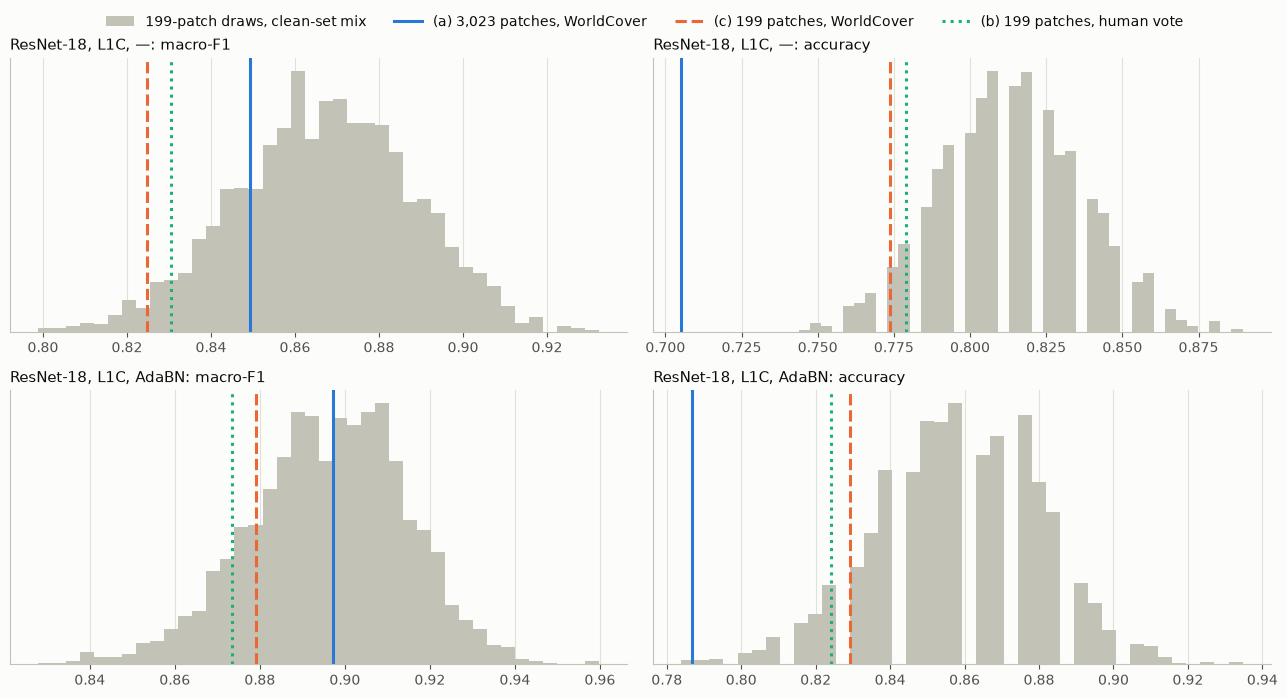

In [6]:
main_runs = [n for n in runs["name"] if n.startswith("ResNet-18, L1C") and n.endswith(("—", "AdaBN"))]
fig, axes = plt.subplots(len(main_runs), 2, figsize=(13, 3.4 * len(main_runs)))
for row, name in enumerate(main_runs):
    acc_s, f1_s = resampled[name]
    for col, (metric, values) in enumerate([("macro_f1", f1_s), ("accuracy", acc_s)]):
        ax = axes[row, col]
        ax.hist(values, bins=40, color=AXIS, label="199-patch draws, clean-set mix")
        for scoring, style in [("worldcover", "-"), ("clean-wc", "--"), ("clean-vote", ":")]:
            ax.axvline(wide.loc[name, (metric, scoring)], color=SCORING_COLORS[scoring], linewidth=2.2, linestyle=style,
                       label=SCORING_NAMES[scoring])
        ax.set_title(f"{name}: {'macro-F1' if metric == 'macro_f1' else 'accuracy'}", loc="left", fontsize=11, color=INK)
        ax.set_yticks([])
        ax.grid(axis="y", visible=False)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
save(fig, "sample_effect_main_model.png")
plt.show()

## 4. How precise is a score on 199 patches, and does the small set rank the methods the same way?

95% bootstrap interval of the macro-F1 on the hand-labelled set (vote labels), for every run. Then the rank correlation (Spearman) of the
14 runs between the scorings: 1 means the same order.

In [7]:
ci_rows = []
for r in runs.itertuples():
    p = codes(preds[r.name].loc[clean.index])
    _, f = scores(Y_VOTE[boot], p[boot])
    ci_rows.append({"run": r.name, "macro-F1 (b)": wide.loc[r.name, ("macro_f1", "clean-vote")],
                    "95% low": np.percentile(f, 2.5), "95% high": np.percentile(f, 97.5)})
ci = pd.DataFrame(ci_rows).set_index("run")
ci["width"] = ci["95% high"] - ci["95% low"]
ci.round(3).to_csv(OUT / "clean_set_intervals.csv")

f1w = wide["macro_f1"]
rank = pd.Series({
    "(a) 3,023 WorldCover vs (b) 199 vote": spearmanr(f1w["worldcover"], f1w["clean-vote"]).statistic,
    "(a) 3,023 WorldCover vs (c) 199 WorldCover": spearmanr(f1w["worldcover"], f1w["clean-wc"]).statistic,
    "(b) 199 vote vs (c) 199 WorldCover": spearmanr(f1w["clean-vote"], f1w["clean-wc"]).statistic,
}, name="Spearman rank correlation of macro-F1 over the runs").round(3)
print(rank.to_string(), "\n")
print(f"width of the 95% interval on 199 patches: {ci['width'].min():.3f} to {ci['width'].max():.3f} macro-F1")
ci.round(3)

(a) 3,023 WorldCover vs (b) 199 vote          0.982
(a) 3,023 WorldCover vs (c) 199 WorldCover    0.982
(b) 199 vote vs (c) 199 WorldCover            1.000 

width of the 95% interval on 199 patches: 0.069 to 0.116 macro-F1


,macro-F1 (b),95% low,95% high,width
run,,,,
"ResNet-18, L1C, —",0.831,0.780,0.873,0.093
"ResNet-18, L1C, AdaBN",0.874,0.829,0.911,0.081
"ResNet-18, L1C, AdaBN + grassland removed",0.934,0.896,0.965,0.069
"ResNet-18, L1C, grassland removed",0.894,0.848,0.932,0.084
"ResNet-18, L1C, Thai normalisation",0.810,0.756,0.855,0.099
"ResNet-18, L1C, Thai normalisation + grassland removed",0.903,0.861,0.940,0.078
"ResNet-18, L2A, —",0.371,0.314,0.426,0.112
"ResNet-18, L2A, B9 set to EuroSAT mean",0.506,0.456,0.549,0.093
"ResNet-18, L2A, B9 set to EuroSAT mean + grassland removed",0.666,0.627,0.706,0.079


In [8]:
# can the 199 patches tell the main methods apart? paired bootstrap of the difference
pairs = [("ResNet-18, L1C, AdaBN", "ResNet-18, L1C, —"),
         ("ResNet-18, L1C, Thai normalisation", "ResNet-18, L1C, —"),
         ("ResNet-18, L1C, AdaBN", "ResNet-18, L1C, Thai normalisation"),
         ("ResNet-18, L1C, —", "Random Forest, L1C, —"),
         ("ResNet-18, L1C, —", "ResNet-18, L2A, —")]
diff_rows = []
for a, b in pairs:
    pa, pb = codes(preds[a].loc[clean.index]), codes(preds[b].loc[clean.index])
    _, fa = scores(Y_VOTE[boot], pa[boot])
    _, fb = scores(Y_VOTE[boot], pb[boot])
    d = fa - fb
    diff_rows.append({"comparison": f"{a}  minus  {b}",
                      "difference on 199 (b)": f1w.loc[a, "clean-vote"] - f1w.loc[b, "clean-vote"],
                      "95% low": np.percentile(d, 2.5), "95% high": np.percentile(d, 97.5),
                      "difference on 3,023 (a)": f1w.loc[a, "worldcover"] - f1w.loc[b, "worldcover"]})
method_diffs = pd.DataFrame(diff_rows).set_index("comparison")
method_diffs["clear on 199?"] = np.where(method_diffs["95% low"] > 0, "yes", np.where(method_diffs["95% high"] < 0, "yes (negative)", "no"))
method_diffs.round(3).to_csv(OUT / "method_differences_on_clean_set.csv")
method_diffs.round(3)

,difference on 199 (b),95% low,95% high,"difference on 3,023 (a)",clear on 199?
comparison,,,,,
"ResNet-18, L1C, AdaBN minus ResNet-18, L1C, —",0.043,0.004,0.082,0.048,yes
"ResNet-18, L1C, Thai normalisation minus ResNet-18, L1C, —",-0.021,-0.064,0.022,-0.005,no
"ResNet-18, L1C, AdaBN minus ResNet-18, L1C, Thai normalisation",0.064,0.025,0.104,0.053,yes
"ResNet-18, L1C, — minus Random Forest, L1C, —",0.049,-0.001,0.100,0.143,no
"ResNet-18, L1C, — minus ResNet-18, L2A, —",0.459,0.395,0.522,0.505,yes


### Figure: the three scorings of every run

Dots: macro-F1 of each scoring. Bar: 95% bootstrap interval of the score on the 199 hand-labelled patches (vote).

saved C:\Users\kanoo\Data_Mining_Project\outputs\a6\three_scorings.png


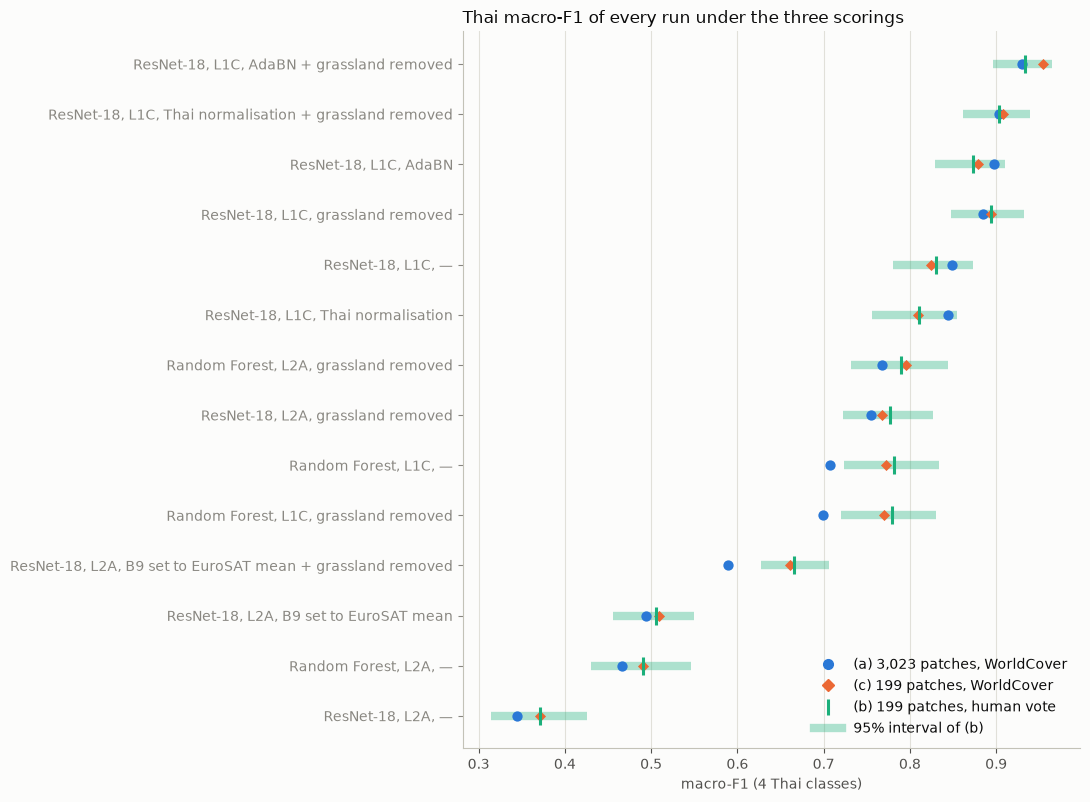

In [9]:
order = f1w.sort_values("worldcover").index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(11, 0.48 * len(order) + 1.4))
ax.hlines(y, ci.loc[order, "95% low"], ci.loc[order, "95% high"], color=SCORING_COLORS["clean-vote"], alpha=0.35, linewidth=6)
for scoring, marker, size in [("worldcover", "o", 55), ("clean-wc", "D", 32), ("clean-vote", "|", 160)]:
    ax.scatter(f1w.loc[order, scoring], y, color=SCORING_COLORS[scoring], marker=marker, s=size, zorder=3,
               label=SCORING_NAMES[scoring], linewidths=2.2 if marker == "|" else 0)
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xlabel("macro-F1 (4 Thai classes)")
ax.set_title("Thai macro-F1 of every run under the three scorings", loc="left", fontsize=12, color=INK)
handles = [Line2D([0], [0], color=SCORING_COLORS["worldcover"], marker="o", linestyle="", markersize=7, label=SCORING_NAMES["worldcover"]),
           Line2D([0], [0], color=SCORING_COLORS["clean-wc"], marker="D", linestyle="", markersize=6, label=SCORING_NAMES["clean-wc"]),
           Line2D([0], [0], color=SCORING_COLORS["clean-vote"], marker="|", linestyle="", markersize=12, markeredgewidth=2.2, label=SCORING_NAMES["clean-vote"]),
           Line2D([0], [0], color=SCORING_COLORS["clean-vote"], alpha=0.35, linewidth=6, label="95% interval of (b)")]
ax.legend(handles=handles, frameon=False, loc="lower right")
fig.tight_layout()
save(fig, "three_scorings.png")
plt.show()

## 5. How reliable are the WorldCover labels of pure patches?

Step A1 found that the vote equals WorldCover on 195 of 199 patches, and on 188 of 189 patches where nobody looked at the WorldCover label.
With a 95% (Wilson) interval:

In [10]:
def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return centre - half, centre + half


agree = clean["consensus"] == clean["worldcover"]
blind = ~clean["any_peeked"].astype(str).str.lower().eq("true")
rows = []
for name, mask in [("all 199 hand-labelled patches", np.ones(len(clean), bool)), ("patches nobody peeked at", blind.to_numpy())]:
    k, n = int(agree[mask].sum()), int(mask.sum())
    lo, hi = wilson(k, n)
    rows.append({"patches": name, "vote = WorldCover": f"{k} of {n}", "share": round(k / n, 3), "95% low": round(lo, 3), "95% high": round(hi, 3)})
reliability = pd.DataFrame(rows).set_index("patches")
reliability.to_csv(OUT / "worldcover_reliability.csv")
reliability

,vote = WorldCover,share,95% low,95% high
patches,,,,
all 199 hand-labelled patches,195 of 199,0.980,0.949,0.992
patches nobody peeked at,188 of 189,0.995,0.971,0.999


## 6. Findings

Written up with their numbers in `outputs/a6/summary.md`.